# Multimodal Authentication and Product Recommendation: the full system

This notebook runs the whole project end to end, from the raw customer data to a granted or denied transaction.
Each section calls the team's scripts in `scripts/`, so the numbers here are the same ones the app uses.
The step-by-step work, with more plots, is in notebooks 01 to 03.

| Part | Member | Script | Detailed notebook |
| --- | --- | --- | --- |
| Data merge and features | Sheja Queen Linda | `merge_pipeline.py` | `01_data_merge_eda.ipynb` |
| Face recognition | Aime Igirimpuhwe | `image_pipeline.py`, `face_model.py` | `02_image_processing_face_model.ipynb` |
| Voice verification | Agnes Mbabazi | `audio_pipeline.py`, `voice_model.py` | `03_audio_processing_voice_model.ipynb` |
| Product model and app | Naillah Ineza | `product_model.py`, `main.py` | this notebook, sections 4 and 5 |

**The flow:** face photo → face recognised → product model runs → voice clip → voice is the same person
saying an approved phrase → the recommended product is shown. Any failed step denies the transaction.

Nothing is retrained or saved here: the evaluations below re-run cross-validation, and the demo loads the saved models.

In [1]:
import sys
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "scripts"))
warnings.filterwarnings("ignore")
pd.set_option("display.width", 140)

import merge_pipeline as mp
import image_pipeline as ip
import face_model as fm
import audio_pipeline as ap
import voice_model as vm
import product_model as pm
import main as app

FIG = ROOT / "figures"
results = {}

## 1. Data: merging the customer tables (Sheja)

The social profiles and the transactions are cleaned, the social data is summarised per customer, and the two are
joined on `customer_id`. The checks below confirm the join did not lose or duplicate transactions.

In [2]:
final, ready, checks = mp.run(save=False)
display(pd.Series(checks, name="value").to_frame())
print(f"Merged dataset: {final.shape[0]} rows x {final.shape[1]} columns")
print(f"Model-ready dataset: {ready.shape[0]} rows x {ready.shape[1]} columns")
display(ready.head())

,value
transactions_rows_before,150
social_customers_after_aggregation,84
customers_in_both,61
customers_only_in_transactions,14
customers_only_in_social,23
transactions_without_social_profile,33
merged_rows,117
merged_customers,61
transaction_id_unique_after_merge,True
nulls_after_merge,0


Merged dataset: 117 rows x 34 columns
Model-ready dataset: 117 rows x 37 columns


,transaction_id,customer_id,purchase_amount,customer_rating,n_social_profiles,n_platforms,avg_engagement,max_engagement,avg_purchase_interest,max_purchase_interest,...,on_linkedin,on_tiktok,on_twitter,top_platform_Facebook,top_platform_Instagram,top_platform_LinkedIn,top_platform_TikTok,top_platform_Twitter,product_category,target_code
0,1001,151,1.00438,-0.67911,1.32132,0.55130,-0.19713,0.10979,-0.87955,0.09224,...,0,1,1,0,0,0,0,1,Sports,4
1,1002,192,0.36877,0.91672,-0.91918,-0.82109,-1.12155,-1.28235,1.18122,0.70146,...,0,0,0,0,1,0,0,0,Electronics,2
2,1003,114,1.28874,-0.84709,-0.91918,-0.82109,1.01782,0.42619,1.66423,1.13662,...,0,0,0,1,0,0,0,0,Electronics,2
3,1005,160,-1.87260,-1.51902,1.32132,1.92370,-0.11789,0.55275,-0.55758,-0.51698,...,1,1,0,0,1,0,0,0,Clothing,1
4,1006,120,0.89566,-1.68700,1.32132,0.55130,0.22546,0.74259,-0.39655,0.09224,...,0,0,0,0,1,0,0,0,Groceries,3


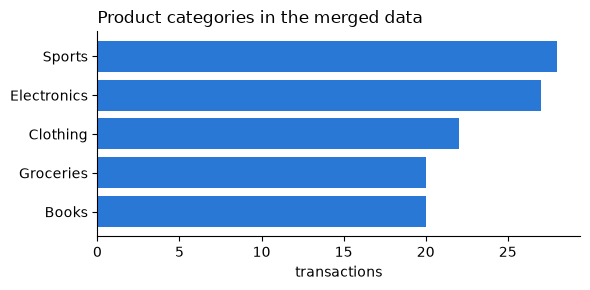

In [3]:
counts = final[mp.TARGET].value_counts()
fig, ax = plt.subplots(figsize=(6, 3))
ax.barh(counts.index[::-1], counts.values[::-1], color="#2a78d6")
ax.set_xlabel("transactions")
ax.set_title("Product categories in the merged data", loc="left")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

## 2. Images: face recognition (Aime)

Every member has a neutral, smiling and surprised photo. Each one gets 5 augmentations, and every version is turned
into a 128-number face embedding by OpenCV's pretrained SFace model.

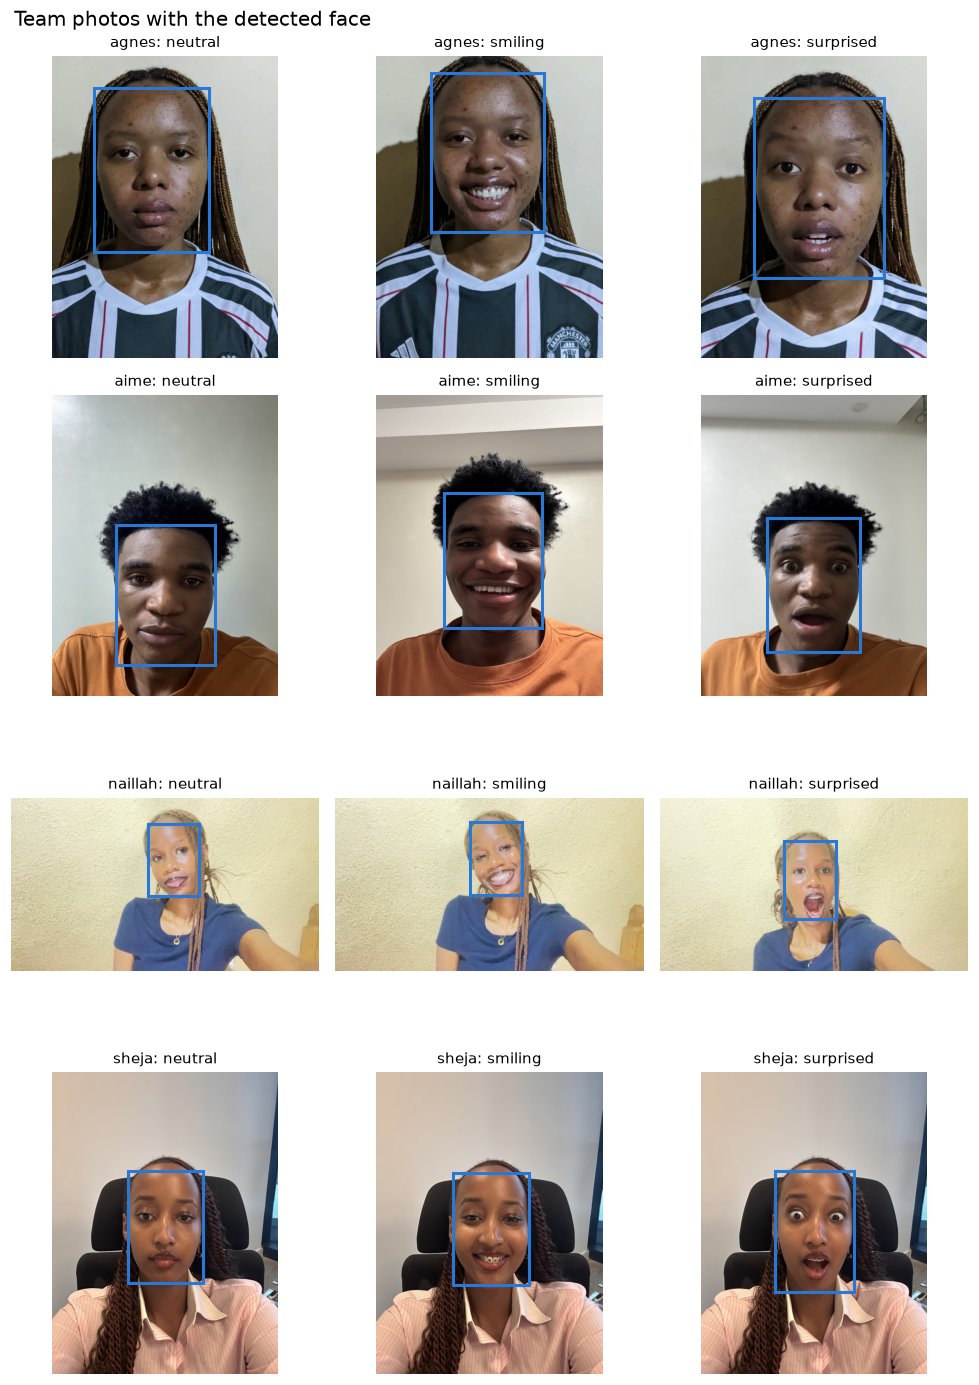

In [4]:
display(Image(filename=str(FIG / "image_01_member_photos.png"), width=620))

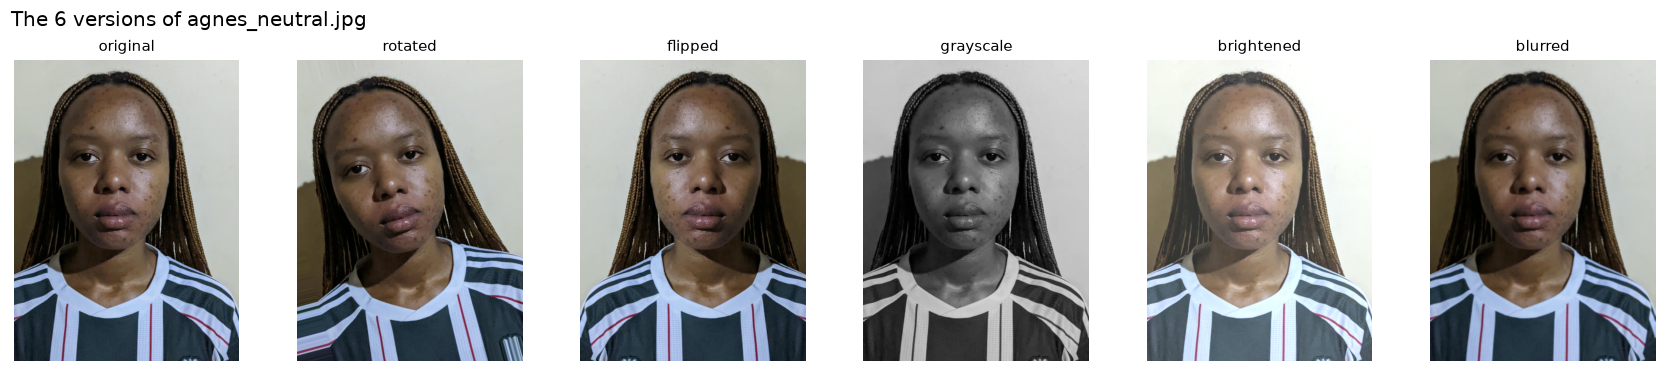

In [5]:
display(Image(filename=str(FIG / "image_02_augmentations.png"), width=760))

In [6]:
faces = pd.read_csv(ip.FEATURES_FILE)
print(f"image_features.csv: {faces.shape[0]} rows, {faces['source_image'].nunique()} photos")
display(pd.crosstab(faces["member"], faces["augmentation"]))

image_features.csv: 72 rows, 12 photos


augmentation,blurred,brightened,flipped,grayscale,original,rotated
member,,,,,,
agnes,3,3,3,3,3,3
aime,3,3,3,3,3,3
naillah,3,3,3,3,3,3
sheja,3,3,3,3,3,3


The model is a Logistic Regression on the embeddings. Each test fold holds out whole photos together with their
augmented copies. A face is accepted only if it is also close enough to that member's own photos (cosine
similarity of at least 0.5), so strangers come back as `"unknown"`.

In [7]:
out, probabilities, classes = fm.evaluate(faces)
face_metrics = fm.metrics(out, probabilities, classes)
results["Face recognition"] = face_metrics
display(pd.Series(face_metrics, name="held-out photos").round(3).to_frame())

strangers = fm.impostor_test(faces).drop(columns="similarities")
print("Each member left out of training and treated as a stranger:")
display(strangers)

face_model = joblib.load(fm.MODEL_FILE)
print("The unauthorized face and its augmentations, through the saved model:")
display(fm.unauthorized_test(face_model))

,held-out photos
accuracy,1.000
f1_macro,1.000
log_loss,0.064
accepted_correctly,1.000
lowest_genuine_similarity,0.725


Each member left out of training and treated as a stranger:


,left_out,images,rejected,highest_similarity
0,agnes,18,18,0.344
1,aime,18,18,0.250
2,naillah,18,18,0.318
3,sheja,18,18,0.281


The unauthorized face and its augmentations, through the saved model:


,image,augmentation,result,closest_member,similarity
0,unauthorized_face.jpg,original,unknown,aime,0.111
1,unauthorized_face.jpg,rotated,unknown,agnes,0.155
2,unauthorized_face.jpg,flipped,unknown,aime,0.163
3,unauthorized_face.jpg,grayscale,unknown,aime,0.110
4,unauthorized_face.jpg,brightened,unknown,naillah,0.110
5,unauthorized_face.jpg,blurred,unknown,naillah,0.113


## 3. Audio: voice verification (Agnes)

Every member recorded "Yes, approve" and "Confirm transaction". Each clip is augmented (pitch, speed, noise),
split into 0.5 s windows, and described by MFCCs, spectral roll-off, centroid, zero-crossing rate and energy.

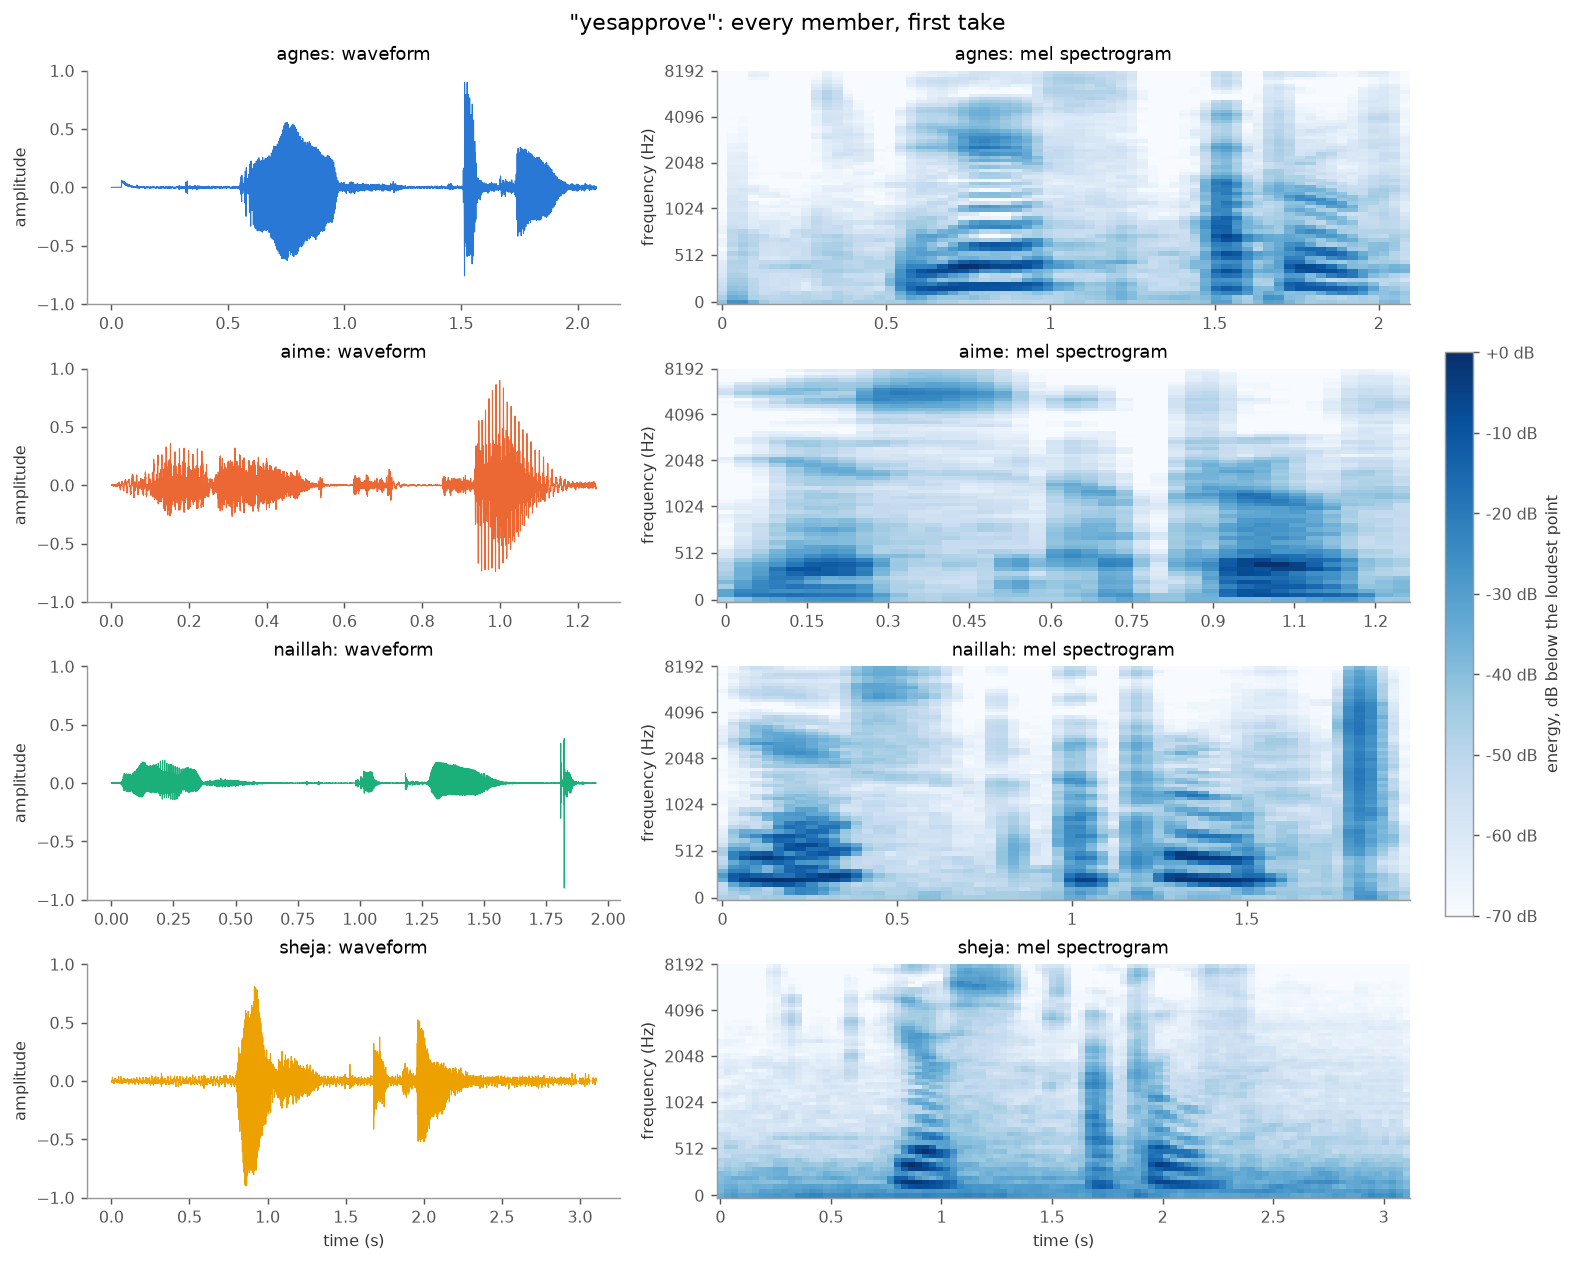

In [8]:
display(Image(filename=str(FIG / "audio_01_yesapprove_waveforms_spectrograms.png"), width=760))

In [9]:
voices = pd.read_csv(ap.FEATURES_FILE)
print(f"audio_features.csv: {voices.shape[0]} window rows, {voices['source_clip'].nunique()} recordings")
display(pd.crosstab(voices["member"], voices["augmentation"]))

audio_features.csv: 768 window rows, 18 recordings


augmentation,faster,noisy,original,pitch_down,pitch_up,slower
member,,,,,,
agnes,36,41,41,41,41,46
aime,21,24,24,24,24,28
naillah,37,42,42,42,42,46
sheja,19,21,21,21,21,23


The voice model is evaluated on whole recordings it never saw. Its speaker threshold is chosen where the false
accept rate (strangers let in) equals the false reject rate (members turned away).

In [10]:
voice_out, voice_classes = vm.evaluate(voices)
voice_metrics = vm.metrics(voice_out, voice_classes)
results["Voice verification"] = voice_metrics
display(pd.Series(voice_metrics, name="held-out recordings").round(3).to_frame())
print(f"Phrase model accuracy on unseen speakers: {vm.phrase_test(voices):.3f}")

impostors = vm.impostor_test(voices)
genuine = vm.genuine_scores(voice_out)
impostor = np.concatenate(impostors["probabilities"].to_list())
threshold, far, frr = vm.choose_threshold(genuine, impostor)
print(f"Speaker threshold {threshold:.2f}: false accept rate {far:.2f}, false reject rate {frr:.2f}")

voice_model = joblib.load(vm.MODEL_FILE)
print("\nThe unauthorized voice and its augmentations, through the saved model:")
display(vm.unauthorized_test(voice_model))

,held-out recordings
accuracy,0.815
f1_macro,0.819
log_loss,0.656


Phrase model accuracy on unseen speakers: 0.593


Speaker threshold 0.62: false accept rate 0.50, false reject rate 0.50

The unauthorized voice and its augmentations, through the saved model:


,clip,augmentation,result,closest_member,probability,phrase,phrase_probability
0,unauthorized_confirmtransaction.wav,original,unauthorized,aime,0.534,confirmtransaction,0.544
1,unauthorized_confirmtransaction.wav,pitch_up,unauthorized,aime,0.449,confirmtransaction,0.550
2,unauthorized_confirmtransaction.wav,pitch_down,unauthorized,agnes,0.450,yesapprove,0.544
3,unauthorized_confirmtransaction.wav,faster,unauthorized,aime,0.443,yesapprove,0.503
4,unauthorized_confirmtransaction.wav,slower,unauthorized,aime,0.379,confirmtransaction,0.503
5,unauthorized_confirmtransaction.wav,noisy,unauthorized,aime,0.410,confirmtransaction,0.519
6,unauthorized_yesapprove.wav,original,unauthorized,aime,0.566,yesapprove,0.916
7,unauthorized_yesapprove.wav,pitch_up,unauthorized,aime,0.487,yesapprove,0.919
8,unauthorized_yesapprove.wav,pitch_down,unauthorized,aime,0.582,yesapprove,0.697
9,unauthorized_yesapprove.wav,faster,unauthorized,aime,0.509,yesapprove,0.907


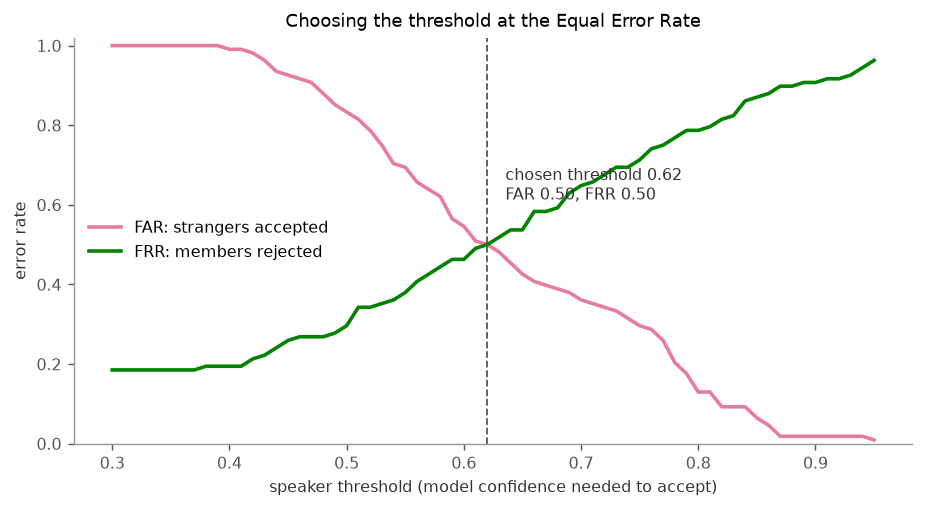

In [11]:
display(Image(filename=str(FIG / "audio_06_far_frr.png"), width=620))

## 4. Product recommendation (Naillah)

A Random Forest predicts the product category from the merged customer features. `GroupKFold` keeps all of a
customer's transactions in the same fold, so the model is always scored on customers it has not seen.
The pattern in this data is weak, so the useful comparison is against always guessing the most common product
and against predicting the class frequencies.

In [12]:
table = pm.load_table()
y = table["target_code"].to_numpy(dtype=int)
predicted, product_probabilities, product_classes, n_splits = pm.cross_validate(table)
product_metrics = pm.metrics(y, predicted, product_probabilities, product_classes)
results["Product recommendation"] = product_metrics
display(pd.Series(product_metrics, name=f"GroupKFold, {n_splits} folds").round(3).to_frame())
print(f"Always predicting the most common product: accuracy {pm.majority_accuracy(y):.3f}")
print(f"Predicting the class frequencies: log loss {pm.base_rate_log_loss(y, product_classes):.3f}")

,"GroupKFold, 5 folds"
accuracy,0.265
f1_macro,0.253
log_loss,1.656


Always predicting the most common product: accuracy 0.239
Predicting the class frequencies: log loss 1.599


## 5. The full system (Naillah's `main.py`)

`run_transaction` is what the command-line app runs. The demo below is one full transaction and three
unauthorized attempts: a stranger's face, a stranger's voice, and a member's face with another member's voice.

In [13]:
_ = app.demo()

Unauthorized face


1. Face: images/raw/unauthorized_face.jpg
   unknown (closest member aime is only 0.11 similar (needs 0.5))

ACCESS DENIED. Face was not recognised. The product model was not called.

Scenario result: as expected.

Unauthorized voice


1. Face: images/raw/sheja_neutral.jpg
   sheja (matches an enrolled member)
2. Product model ran for customer 187, transaction 1135. The recommendation is hidden until the voice matches.
3. Voice: audio/raw/unauthorized_yesapprove.m4a
   unauthorized (closest member aime is only 0.57 likely (needs 0.62))

ACCESS DENIED. Voice was not approved. The recommendation stays hidden.

Scenario result: as expected.

Different person on the voice check


1. Face: images/raw/sheja_neutral.jpg
   sheja (matches an enrolled member)
2. Product model ran for customer 187, transaction 1135. The recommendation is hidden until the voice matches.
3. Voice: audio/raw/aime_yesapprove.m4a
   aime (matches an enrolled member saying an approved phrase)

ACCESS DENIED. Face is sheja but the voice is aime. Both checks must be the same person. The recommendation stays hidden.

Scenario result: as expected.

Full transaction


1. Face: images/raw/sheja_neutral.jpg
   sheja (matches an enrolled member)
2. Product model ran for customer 187, transaction 1135. The recommendation is hidden until the voice matches.
3. Voice: audio/raw/sheja_yesapprove.m4a
   sheja (matches an enrolled member saying an approved phrase)

ACCESS GRANTED. Face and voice are the same person. The recommendation can be shown.
Recommended product: Books
   Books          0.69
   Sports         0.14
   Groceries      0.10
   Clothing       0.05
   Electronics    0.02

Scenario result: as expected.

Demo passed: the full transaction was shown, and the three unauthorized attempts were denied.


Every member's face against every member's voice. Only the diagonal, where the face and the voice belong to
the same person, should be granted.

In [14]:
members = sorted(faces["member"].unique())
customer = pm.default_customer_id()
grid = pd.DataFrame(index=members, columns=members, dtype=object)
for face_member in members:
    for voice_member in members:
        result = app.run_transaction(ip.RAW / f"{face_member}_smiling.jpg",
                                     ROOT / "audio" / "raw" / f"{voice_member}_yesapprove.m4a", customer_id=customer)
        grid.loc[face_member, voice_member] = "granted" if result["granted"] else "denied"
grid.index.name, grid.columns.name = "face", "voice"
display(grid)
assert all((grid.loc[f, v] == "granted") == (f == v) for f in members for v in members)
print("Only matching face and voice pairs were granted.")

voice,agnes,aime,naillah,sheja
face,,,,
agnes,granted,denied,denied,denied
aime,denied,granted,denied,denied
naillah,denied,denied,granted,denied
sheja,denied,denied,denied,granted


Only matching face and voice pairs were granted.


## 6. Results at a glance

In [15]:
display(pd.DataFrame(results).T[["accuracy", "f1_macro", "log_loss"]].round(3))

,accuracy,f1_macro,log_loss
Face recognition,1.000,1.000,0.064
Voice verification,0.815,0.819,0.656
Product recommendation,0.265,0.253,1.656


**Face recognition** separates the four members on held-out photos and rejects every stranger.
**Voice verification** is the weaker check: with a few phone recordings per person it confuses some speakers,
and on its own it would let some stranger clips through. **The product model** barely beats always guessing the
most common product, and its log loss is no better than predicting the class frequencies: the customer data only
carries a weak pattern, as the EDA in notebook 01 found.

That is why a transaction needs the face *and* the voice of the same member: the strong face check guards the
door, and the voice must still agree with it, so a stranger has to beat both.